# 10 · Сегментация и рекомендация

Шаг 11–12 плана. Порог high-value — число, обоснованное покрытием выручки holdout:
беру минимальный верхний сегмент, который собирает 60 % фактической выручки.
Отдельно — сегмент B (одна покупка) и shrinkage прогноза к среднему по группе
«страна × бэнд первого чека».

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
import json
from inspect import signature
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from paths import CASE_LTV, PROCESSED, RANDOM_SEED, figures
from features import (CUTOFF_DATE, HORIZON_MONTHS, B3_T_DAYS, B3_FIT_MONTHS,
                      DAYS_IN_AGE_MONTH, split_transactions, calibration_features,
                      calibration_revenue, build_target, lifecycle_transactions,
                      first_purchase_dates, pre_first_mask, customer_country,
                      cohort_tables, pooled_curve, extend_survival,
                      extend_cumulative_revenue, age_months)
from metrics import (gini, top_capture, top_lift, decile_capture, lorenz_points,
                     mae, rmse, calibration_ratio, model_metrics, bootstrap_ci,
                     bootstrap_diff, calibration_by, coverage_at_top,
                     smallest_segment_for_coverage, shrink_predictions)
from models import (fit_bgnbd, fit_mbg_nbd, fit_pareto_nbd, fit_gamma_gamma,
                    bgnbd_loglik, bgnbd_expected_purchases, mbg_nbd_loglik,
                    mbg_nbd_expected_purchases, pareto_nbd_loglik,
                    pareto_nbd_expected_purchases, gamma_gamma_loglik,
                    gamma_gamma_mean, gamma_gamma_conditional_spend,
                    monthly_expected_purchases, discounted_revenue, aic)
from plots import (plot_split_timeline, plot_lorenz, plot_model_comparison,
                   plot_calibration_by_decile, plot_horizon, plot_segments,
                   plot_shrinkage, plot_posterior)
FIG = figures(CASE_LTV); FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(RANDOM_SEED)
tx = pd.read_parquet(PROCESSED / 'transactions.parquet')

split = pd.read_parquet(PROCESSED / 'ltv_split.parquet')
val = pd.read_parquet(PROCESSED / 'validation.parquet')
d = split.join(val[['BG', 'B1', 'spend_main']])
y = d.revenue_holdout.to_numpy(float)


## Порог high-value по покрытию 60 % выручки

In [2]:
seg = smallest_segment_for_coverage(y, d.BG.to_numpy(), target=0.60)
print('k:', seg['k'], '· доля клиентов:', f"{seg['share_customers']:.1%}",
      '· покрытие:', f"{seg['coverage']:.1%}", '· порог:', round(seg['threshold'], 1), '£')
threshold = float(np.floor(seg['threshold'] / 10) * 10)
print('порог, округлённый до £10:', threshold, '£')


k: 415 · доля клиентов: 9.8% · покрытие: 60.0% · порог: 3586.1 £
порог, округлённый до £10: 3580.0 £


In [3]:
d['high_value'] = d.BG >= threshold
d['one_purchase'] = d.frequency == 0
d['segment'] = np.select([d.high_value, d.one_purchase], ['high-value', 'B (одна покупка)'], default='остальные')
seg_table = d.groupby('segment', observed=True).agg(
    customers=('BG', 'size'),
    customers_share=('BG', lambda s: len(s) / len(d)),
    predicted_ltv_share=('BG', lambda s: s.sum() / d.BG.sum()),
    revenue_share=('revenue_holdout', lambda s: s.sum() / y.sum()),
    mean_actual=('revenue_holdout', 'mean'),
    median_actual=('revenue_holdout', 'median'),
).reset_index()
seg_table.round(3)


,segment,customers,customers_share,predicted_ltv_share,revenue_share,mean_actual,median_actual
0,B (одна покупка),1480,0.349,0.125,0.063,275.878,0.00
1,high-value,417,0.098,0.478,0.601,9408.707,4280.76
2,остальные,2342,0.552,0.397,0.336,936.616,452.91


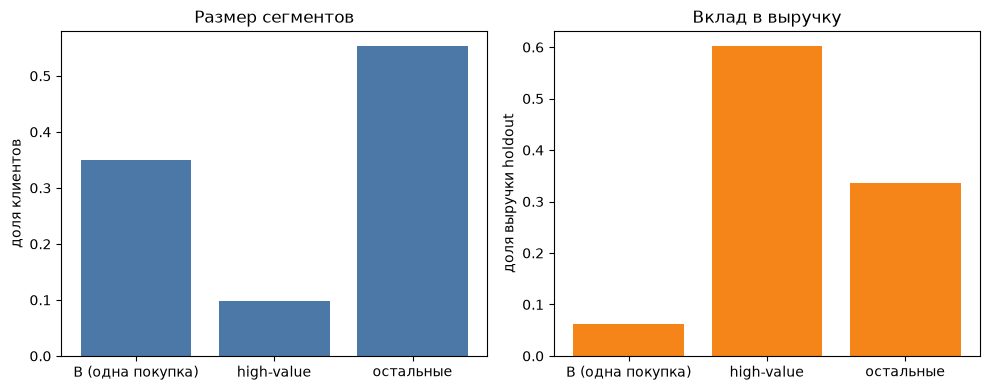

In [4]:
plot_segments(seg_table, FIG / '16-segments.png')
plt.show()


## Сегмент B: shrinkage к группе «страна × бэнд первого чека»

Для клиента с одной покупкой индивидуальный прогноз переобучен. Shrinkage:
`w = n/(n+10)`, где n — число дней с покупкой; для сегмента B w ≈ 0.09, то есть
прогноз почти равен среднему группы. Группа — страна × квартиль первого чека.

In [5]:
first_check = d.spend_main  # для группировки ниже используется первый чек из spend.parquet
spend = pd.read_parquet(PROCESSED / 'spend.parquet')
d['first_check'] = spend['first_check'].reindex(d.index)
d['first_check_band'] = pd.qcut(d.first_check.rank(method='first'), 4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
d['group'] = d.country.astype(str) + ' × ' + d.first_check_band.astype(str)
n_obs = (d.frequency + 1).clip(lower=1)
d['BG_shrunk'] = shrink_predictions(d.BG, d.group, n_obs, k=10)
b = d[d.segment == 'B (одна покупка)']
print('B: n', len(b), '· Gini до', round(gini(b.revenue_holdout, b.BG), 4),
      '· после', round(gini(b.revenue_holdout, b.BG_shrunk), 4))
print('B: MAE до', round(mae(b.revenue_holdout, b.BG), 1),
      '· после', round(mae(b.revenue_holdout, b.BG_shrunk), 1))


B: n 1480 · Gini до 0.3084 · после 0.3645
B: MAE до 648.1 · после 1516.0


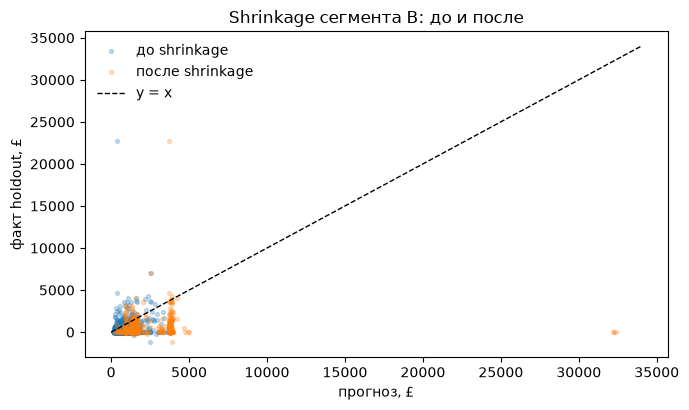

In [6]:
plot_shrinkage(b.BG.to_numpy(), b.BG_shrunk.to_numpy(), b.revenue_holdout.to_numpy(),
               FIG / '17-shrinkage-segment-b.png')
plt.show()


Shrinkage меняет не только уровень, но и ranking внутри B: индивидуальный
прогноз одной транзакции шумный, групповое среднее устойчивее.

## Рекомендация: цифра и что меняется от действия

In [7]:
hv = d[d.high_value]
median_hv = float(hv.revenue_holdout.median())
margin = 0.30
cac_cap = margin * median_hv
print('high-value: клиентов', len(hv), f'({len(hv)/len(d):.1%})',
      '· покрытие выручки', f'{hv.revenue_holdout.sum()/y.sum():.1%}')
print('медианная фактическая выручка holdout в сегменте:', round(median_hv, 1), '£')
print('CAC cap при марже 30 %:', round(cac_cap, 1), '£ на клиента')


high-value: клиентов 417 (9.8%) · покрытие выручки 60.1%
медианная фактическая выручка holdout в сегменте: 4280.8 £
CAC cap при марже 30 %: 1284.2 £ на клиента


In [8]:
recommendation = {
    'threshold_gbp': threshold,
    'segment_share': float(len(hv) / len(d)),
    'revenue_coverage': float(hv.revenue_holdout.sum() / y.sum()),
    'median_holdout_revenue_gbp': median_hv,
    'gross_margin_assumption': margin,
    'cac_cap_gbp': cac_cap,
    'notice': 'рост бюджета на сегмент поднимает CAC; при CAC выше cap сегмент перестаёт окупаться',
}
(PROCESSED / 'recommendation.json').write_text(json.dumps(recommendation, ensure_ascii=False, indent=2), encoding='utf-8')
seg_table.to_csv(PROCESSED / 'segments.csv', index=False)
d[['segment', 'BG', 'BG_shrunk', 'revenue_holdout', 'high_value', 'one_purchase']].to_parquet(PROCESSED / 'segments.parquet')
recommendation


{'threshold_gbp': 3580.0,
 'segment_share': 0.0983722576079264,
 'revenue_coverage': 0.6012658230563924,
 'median_holdout_revenue_gbp': 4280.76,
 'gross_margin_assumption': 0.3,
 'cac_cap_gbp': 1284.228,
 'notice': 'рост бюджета на сегмент поднимает CAC; при CAC выше cap сегмент перестаёт окупаться'}

**Что меняется от самого действия.** Рост бюджета на high-value сегмент
повышает CAC: аукцион и частота контакта дорожают, а часть сегмента уже купила бы
без стимула. Поэтому рекомендация — не «увеличить бюджет на сегмент», а «держать
CAC ниже £X и перераспределять бюджет только пока предельный CAC ниже cap».
Это общая форма ошибки Альфа-Банка: высокий прогноз дохода не является разрешением
на действие без модели издержек.

Ограничение: маржа 30 % — сценарное допущение, в данных её нет. В README
число помечено как assumption, а не как измеренная величина.